### data loading and inspecting

In [33]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
print("Importing completed!")

Importing completed!


In [34]:
df = pd.read_csv('student_dataset.csv')
df.head()

,student_id,gender,age,study_hours_per_week,sleep_hours_per_night,attendance_percent,internet_at_home,extracurricular_activities,past_failures,final_score
0,S001,Male,16,2.5,7.6,89,No,Yes,0,48
1,S002,Male,17,8.5,5.9,96,Yes,No,2,57
2,S003,Male,17,6.1,7.0,86,Yes,Yes,0,59
3,S004,Female,16,6.7,7.7,99,Yes,Yes,0,70
4,S005,Female,17,8.8,7.5,94,Yes,No,0,71


In [35]:
print(f"Total potential features: {df.shape[1]}")
print(f"Total sample data: {df.shape[0]}")

Total potential features: 10
Total sample data: 500


In [36]:
df.isnull().sum()

student_id                    0
gender                        0
age                           0
study_hours_per_week          0
sleep_hours_per_night         0
attendance_percent            0
internet_at_home              0
extracurricular_activities    0
past_failures                 0
final_score                   0
dtype: int64

In [37]:
df.duplicated().sum()

np.int64(0)

no duplicates and nan contains

In [38]:
df.describe()

,age,study_hours_per_week,sleep_hours_per_night,attendance_percent,past_failures,final_score
count,500.000000,500.000000,500.000000,500.000000,500.000000,500.000000
mean,16.292000,6.978400,6.986800,89.702000,0.390000,61.226000
std,1.014295,3.739479,1.001135,7.414523,0.717586,10.918303
min,15.000000,1.100000,4.000000,66.000000,0.000000,28.000000
25%,15.000000,4.200000,6.300000,84.000000,0.000000,54.000000
50%,16.000000,6.200000,7.000000,90.000000,0.000000,61.000000
75%,17.000000,9.100000,7.700000,96.000000,1.000000,68.000000
max,18.000000,23.200000,9.800000,100.000000,3.000000,98.000000


In [39]:
df.describe(include='object')

C:\Users\Nazmul Hasan\AppData\Local\Temp\ipykernel_1864\87514550.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  df.describe(include='object')


,student_id,gender,internet_at_home,extracurricular_activities
count,500,500,500,500
unique,500,2,2,2
top,S001,Male,Yes,No
freq,1,250,398,251


### What does a typical student look like?

In [40]:
df['final_score'].describe()

count    500.000000
mean      61.226000
std       10.918303
min       28.000000
25%       54.000000
50%       61.000000
75%       68.000000
max       98.000000
Name: final_score, dtype: float64

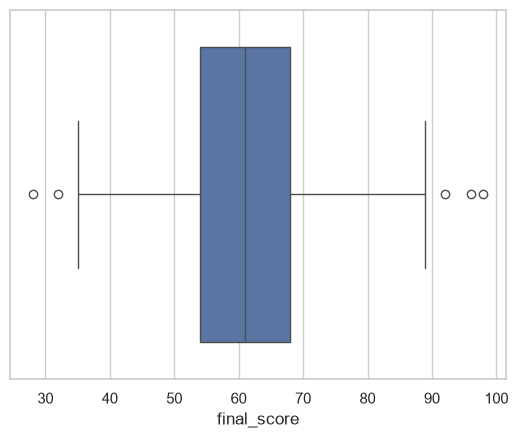

In [41]:
sns.boxplot(data=df, x='final_score')
plt.show()

a typical students average marks around 62, some students are getting above 90 and some are less the 40

### Do students who study more score higher?

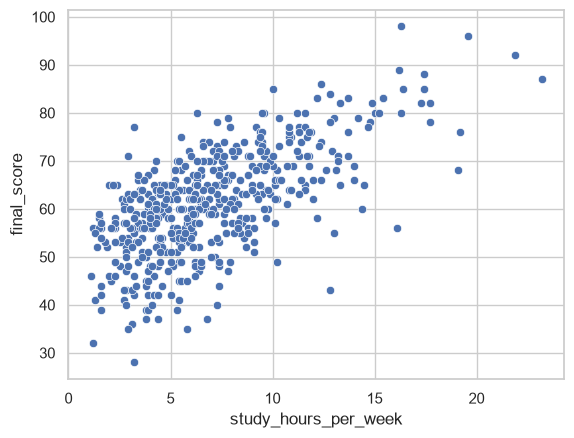

In [42]:
sns.scatterplot(data=df, x='study_hours_per_week', y='final_score')
plt.show()

marks are increasing when the study hours per week is increasing, there is a postive relation between them

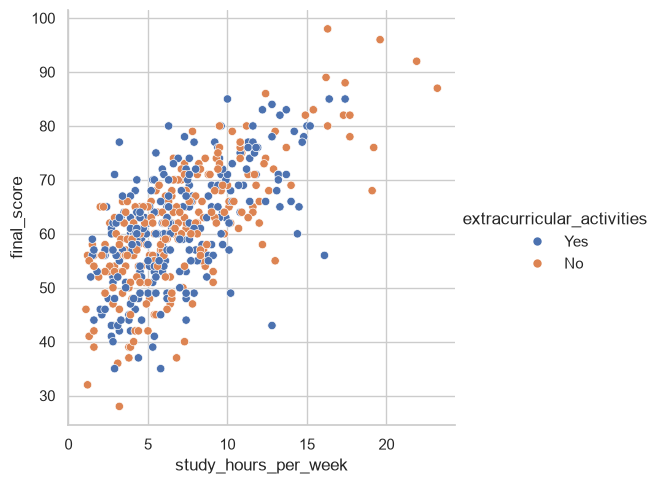

In [43]:
sns.relplot(kind='scatter',data=df, x='study_hours_per_week', y='final_score', hue='extracurricular_activities')
plt.show()

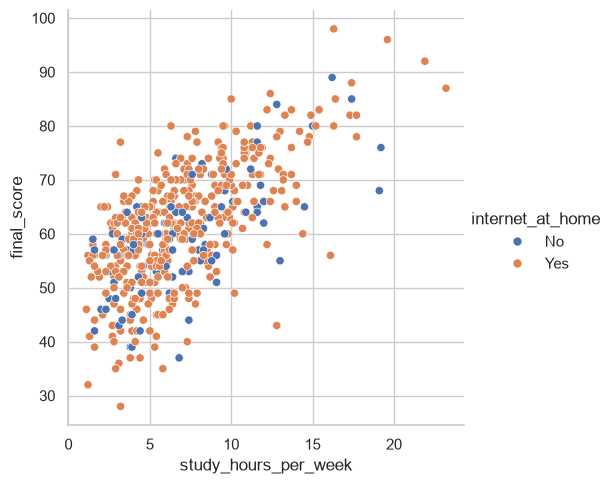

In [44]:
sns.relplot(kind='scatter',data=df, x='study_hours_per_week', y='final_score', hue='internet_at_home')
plt.show()

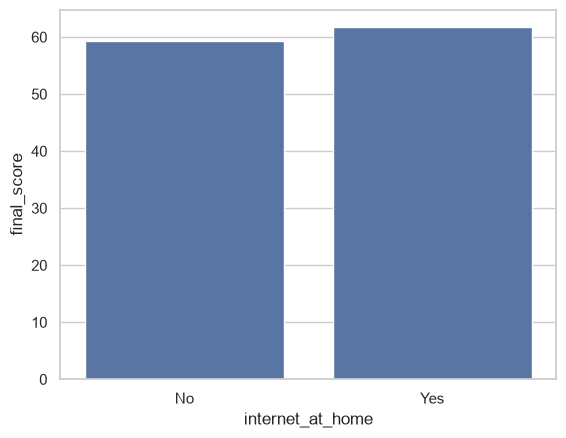

In [45]:
internet_at_home = (
    df.groupby("internet_at_home")["final_score"]
      .mean()
      .reset_index()
)

sns.barplot(data=internet_at_home, x="internet_at_home", y="final_score")
plt.show()

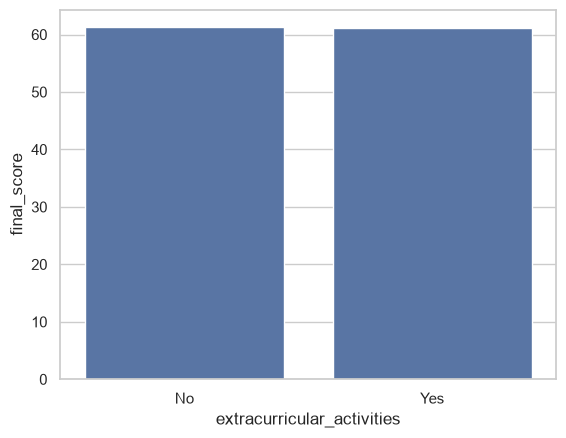

In [46]:
extracurricular_activities = (
    df.groupby("extracurricular_activities")["final_score"]
      .mean()
      .reset_index()
)

sns.barplot(data=extracurricular_activities, x="extracurricular_activities", y="final_score")
plt.show()

There are subtle difference based on to do extracurricular_activities or not and the access to the internet at home to the final marks

### Which factor seems to matter most overall?

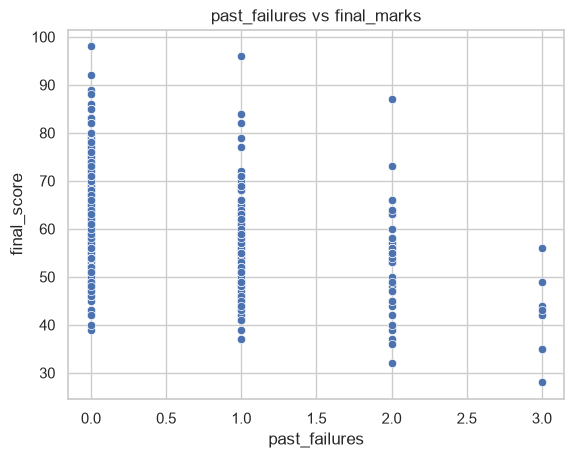

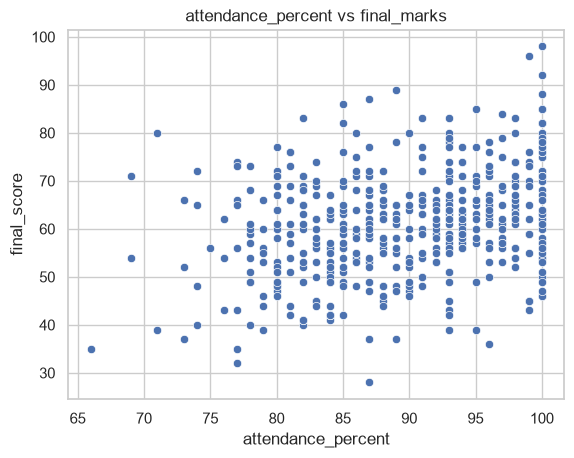

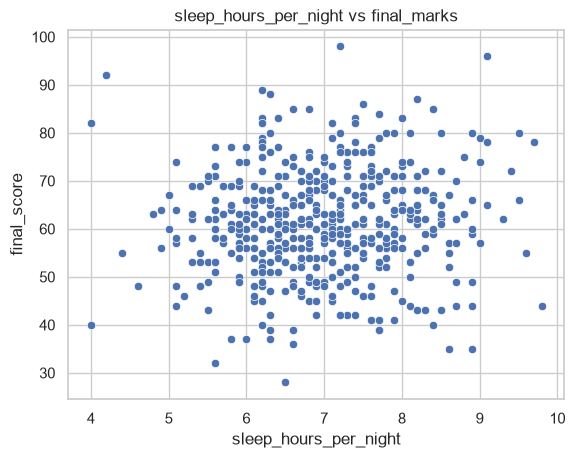

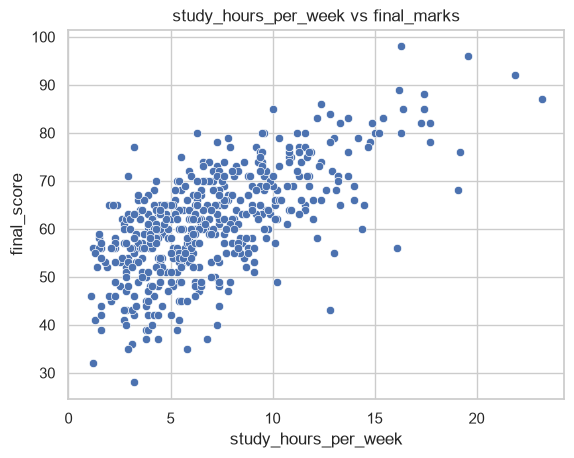

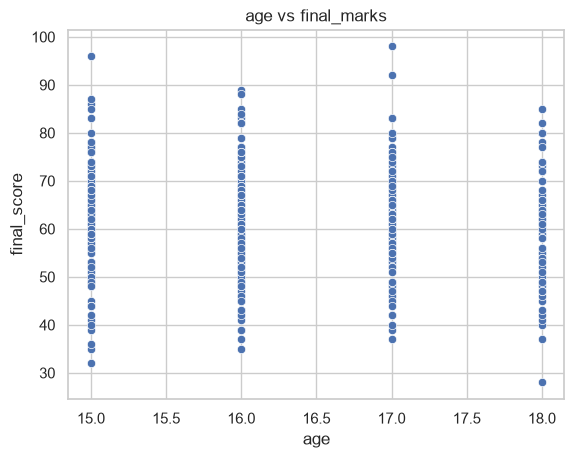

In [47]:
num_cols = ["past_failures", "attendance_percent", "sleep_hours_per_night", "study_hours_per_week", "age"]

for col in num_cols:
    sns.scatterplot(data=df, x=col, y='final_score')
    plt.title(col + " vs final_marks")
    plt.show()

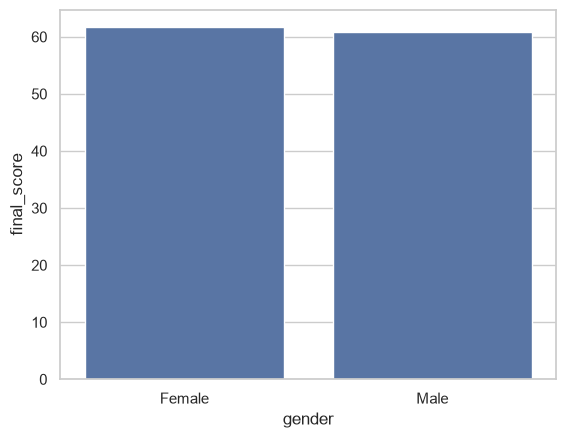

In [48]:
gender = (
    df.groupby("gender")["final_score"]
      .mean()
      .reset_index()
)

sns.barplot(data=gender, x="gender", y="final_score")
plt.show()

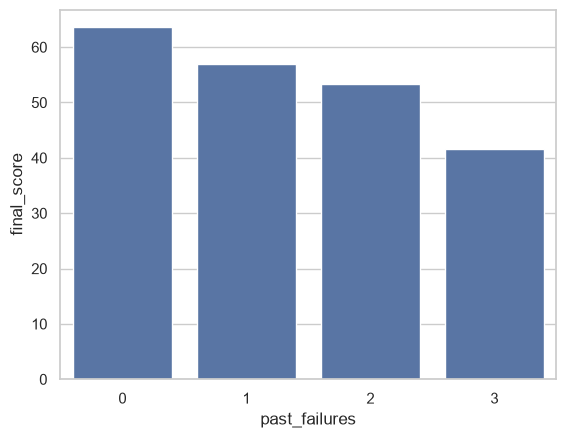

In [49]:
past_failures = (
    df.groupby("past_failures")["final_score"]
      .mean()
      .reset_index()
)

sns.barplot(data=past_failures, x="past_failures", y="final_score")
plt.show()

In [50]:
past_failures = (
    df.groupby("past_failures")["final_score"]
      .mean()
      .reset_index()
)

past_failures

,past_failures,final_score
0,0,63.589041
1,1,57.011905
2,2,53.333333
3,3,41.555556


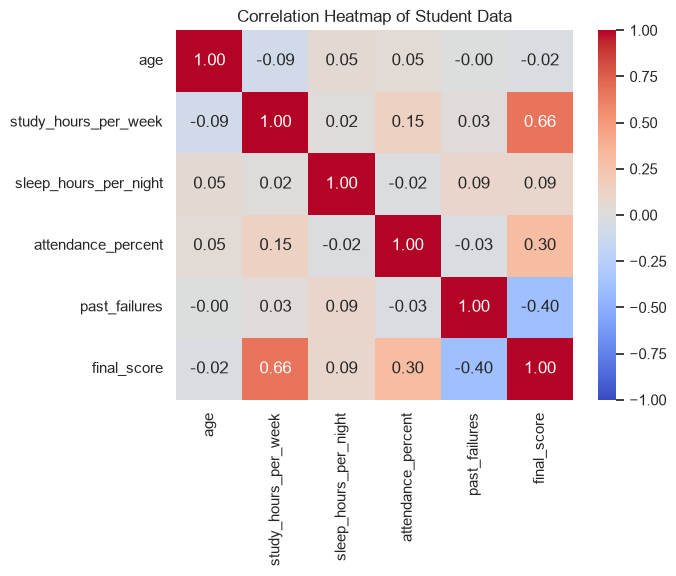

In [51]:
numeric_df = df.select_dtypes(include="number")

corr = numeric_df.corr()

sns.heatmap(
    corr,
    annot=True,        # show the numbers in each cell
    fmt=".2f",         # round to 2 decimals
    cmap="coolwarm",   # red = positive, blue = negative
    vmin=-1, vmax=1,   # fixed scale so colors are comparable
    center=0
)
plt.title("Correlation Heatmap of Student Data")
plt.show()

In [53]:
ranking = (
    corr["final_score"]
    .drop("final_score")
    .sort_values(key=abs, ascending=False)
)
print(ranking.round(2))

study_hours_per_week     0.66
past_failures           -0.40
attendance_percent       0.30
sleep_hours_per_night    0.09
age                     -0.02
Name: final_score, dtype: float64


Past failures is mattter most to final result at a decreasing (-0.40) relation. Moreover study hours (0.66) and attendance (0.30) also in a postive relationship with final score, that means it is also impacts the final result.